# Subgrupo B · Caja negra + explicaciones post-hoc (XGBoost)

*Gradient boosting* (XGBoost) explicado con SHAP, LIME y contrafactuales (DiCE), con comprobación de equidad por edad, lista de auditoría y borrador de *model card* (apartados 3.2–3.5 y 4.1–4.3 de la wiki).

Usa el protocolo común (`common_protocol.py`): misma partición 80/20, misma validación cruzada repetida y mismo criterio de umbral que el resto de modelos. **Requisito:** haber ejecutado antes el notebook del protocolo común (hasta 1.6).

Guarda en el Drive:
- `results/`: resultados en el formato común y tablas propias (terminadas en `_B_XGBoost.csv`).
- `graphics/`: gráficos (empiezan por `B_<apartado>_XGBoost_`).

Las celdas marcadas con ✏️ son las que hay que completar con vuestra interpretación.

# Configuración

Instala las librerías, conecta el Drive e importa el protocolo común

In [58]:
%pip install -q xgboost shap lime dice-ml

In [59]:
import os, sys, importlib
# Carpeta compartida del grupo en Google Drive
FOLDER = "/content/drive/MyDrive/Seminario_IAO"
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    FOLDER = "Seminario_IAO"          # si se ejecuta fuera de Colab
os.makedirs(FOLDER, exist_ok=True)
if FOLDER not in sys.path:
    sys.path.insert(0, FOLDER)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [60]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, brier_score_loss
from xgboost import XGBClassifier
import shap
from lime.lime_tabular import LimeTabularExplainer
import dice_ml

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

importlib.invalidate_caches()
import common_protocol as pc
importlib.reload(pc)
R = pc.routes(FOLDER)                              # subcarpetas: common/, results/, graphics/
SUBGROUP, MODEL = "B", "XGBoost"

def storage(section, name):
    # Guarda el gráfico actual en graphics/ como B_<apartado>_XGBoost_<name>.png
    plt.savefig(os.path.join(R["graphics"], f"B_{section}_{MODEL}_{name}.png")); plt.show()

def storage_csv(df, name, **kw):
    # Guarda una tabla en results/ como <name>_B_XGBoost.csv
    df.to_csv(os.path.join(R["results"], f"{name}_{SUBGROUP}_{MODEL}.csv"), **kw)

X_train, X_test, y_train, y_test = pc.load_partition(FOLDER)
COLS_NUM, COLS_CAT = pc.columns(X_train)
COLUMNS = list(X_train.columns)
print(f"Entrenamiento: {len(y_train)} · test: {len(y_test)} · semilla {pc.SEED}")

Entrenamiento: 800 · test: 200 · semilla 42


## 3.3. Entrenamiento del *gradient boosting* (XGBoost)

Rejilla pequeña de hiperparámetros evaluada con la validación cruzada común (solo entrenamiento, el test no se toca). Se elige la configuración con mejor **AUC medio**, que no depende del umbral.

In [61]:
def create_xgb(max_depth=3, n_estimators=300, learning_rate=0.05):
    # Devuelve una función que crea un modelo nuevo sin entrenar (lo que pide pc.evaluate_cv)
    return lambda: Pipeline([
        ("prep", pc.create_preprocess(X_train)),
        ("model", XGBClassifier(max_depth=max_depth, n_estimators=n_estimators, learning_rate=learning_rate,
                                subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
                                random_state=pc.SEED, n_jobs=-1))])

grid = [dict(max_depth=d, n_estimators=n, learning_rate=lr)
        for d in (2, 3, 4) for n in (150, 300) for lr in (0.03, 0.1)]
rows = []
for params in grid:
    table, thres_g, _ = pc.evaluate_cv(create_xgb(**params), X_train, y_train)
    rows.append({**params, "AUC medio": table["AUC"].mean(), "AUC desv.": table["AUC"].std(),
                 "Coste medio": table["Coste medio"].mean(), "umbral": thres_g})
search = pd.DataFrame(rows).sort_values("AUC medio", ascending=False)
storage_csv(search, "busqueda_hiperparametros", index=False)
b = search.iloc[0]
BEST = {"max_depth": int(b.max_depth), "n_estimators": int(b.n_estimators), "learning_rate": float(b.learning_rate)}
print("Mejor configuración:", BEST)
search.round(3).head(6)

Mejor configuración: {'max_depth': 4, 'n_estimators': 150, 'learning_rate': 0.03}


,max_depth,n_estimators,learning_rate,AUC medio,AUC desv.,Coste medio,umbral
8,4,150,0.03,0.792,0.030,0.523,0.14
2,2,300,0.03,0.791,0.032,0.519,0.15
6,3,300,0.03,0.791,0.032,0.538,0.13
10,4,300,0.03,0.790,0.032,0.522,0.09
1,2,150,0.10,0.789,0.036,0.531,0.08
4,3,150,0.03,0.788,0.030,0.528,0.13


## 3.4. Resultados

Primero la validación cruzada (media ± desviación, para ver la variabilidad). Después **una única** evaluación en el test con el umbral elegido en la validación cruzada.

Umbral elegido (mínimo coste en validación cruzada): 0.14 · teórico: 0.167
Brier en test: 0.161
Referencia con umbral 0,5 en test: {'AUC': 0.794, 'Sensibilidad (bad)': 0.433, 'Especificidad (good)': 0.907, 'Coste medio': 0.915}


,Validación cruzada,Test
AUC,0.792 ± 0.030,0.794
Sensibilidad (bad),0.915 ± 0.034,0.917
Especificidad (good),0.435 ± 0.038,0.386
Coste medio,0.523 ± 0.043,0.555


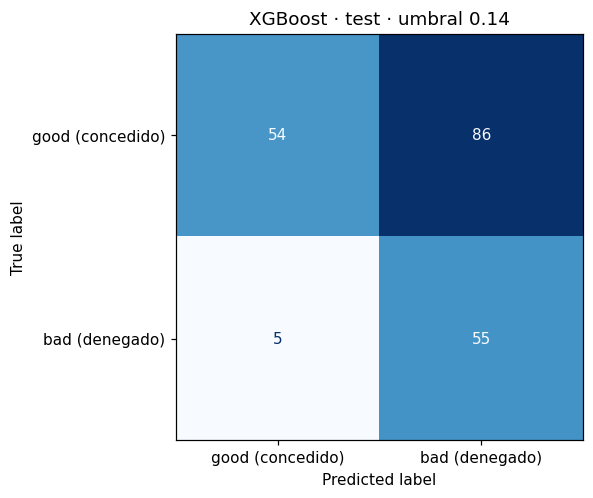

In [62]:
table_cv, thres, oof = pc.evaluate_cv(create_xgb(**BEST), X_train, y_train)
print(f"Umbral elegido (mínimo coste en validación cruzada): {thres:.2f} · teórico: {pc.THE_THRES:.3f}")

model = create_xgb(**BEST)().fit(X_train, y_train)
p_test = pd.Series(model.predict_proba(X_test)[:, 1], index=X_test.index)
res_test = pc.metrics(y_test, p_test, thres)
pc.storage_results(FOLDER, SUBGROUP, MODEL, table_cv, thres, res_test)

# Predicciones del test (mismo formato que el subgrupo A)
pd.DataFrame({"index": X_test.index, "bad": y_test.values, "prob_bad": p_test.values,
              "decision": np.where(p_test >= thres, "denegar", "conceder")}).to_csv(
    os.path.join(R["results"], f"predicciones_{SUBGROUP}_{MODEL}.csv"), index=False)

print(f"Brier en test: {brier_score_loss(y_test, p_test):.3f}")
print("Referencia con umbral 0,5 en test:", {k: round(v, 3) for k, v in pc.metrics(y_test, p_test, 0.5).items()})
display(pd.DataFrame({"Validación cruzada": pc.summary_csv(table_cv), "Test": pd.Series(res_test).round(3)}))

ConfusionMatrixDisplay(confusion_matrix(y_test, (p_test >= thres).astype(int)),
                       display_labels=["good (concedido)", "bad (denegado)"]).plot(cmap="Blues", colorbar=False)
plt.title(f"XGBoost · test · umbral {thres:.2f}")
storage("3_4", "matriz_confusion")

**Interpretación (3.4)**

- **Rendimiento:** AUC de 0,792 ± 0,030 en validación cruzada y 0,794 en test; el modelo ordena bien a los clientes por riesgo y el resultado del test cae dentro de lo esperado.
- **Hiperparámetros:** las 6 mejores configuraciones de la rejilla quedan dentro de 0,004 de AUC entre sí. La elección concreta apenas importa; no hay riesgo de haber «afinado» el modelo a la suerte de una partición.
- **Umbral y coste:** el umbral por coste es 0,14 (cerca del teórico, 0,17). Con él, el modelo detecta el 92 % de los impagos a cambio de denegar a muchos buenos pagadores (solo concede al 39 % de los buenos en test). Coste medio en test 0,555 frente a 0,70 del modelo de referencia (denegar a todos): un ahorro del 21 %. Con el umbral habitual de 0,5 el coste sube a 0,915, **peor que denegar a todos**, porque deja pasar a más de la mitad de los impagos. El umbral importa más que el modelo.
- **Comparación con el subgrupo A:** en validación cruzada el XGBoost queda ligeramente por encima (AUC 0,792 frente a 0,777 la logística y 0,780 el EBM), pero la diferencia es menor que la desviación entre particiones (0,03–0,04). En test, la logística y el EBM lo superan (AUC 0,805 y 0,804; coste 0,535 la logística). **La caja negra no compra una precisión apreciable en este problema.**

## 4.1. Casos individuales

Los tres solicitantes tienen que ser **los mismos en todos los modelos**. Si ya existe `common/individual_cases.csv` (acordado con el subgrupo A), se usa ese. Si no existe, se proponen con el XGBoost (aprobado más claro, denegado más claro y el más cercano al umbral) y se guardan ahí para que A los use.

In [63]:
cases_path = os.path.join(R["common"], "individual_cases.csv")
if os.path.exists(cases_path):
    cases_df = pd.read_csv(cases_path)
    CASES = dict(zip(cases_df["caso"], cases_df["index"]))
    print("Casos leídos de common/individual_cases.csv:", CASES)
else:
    CASES = {"aprobado": int(p_test[y_test == 0].idxmin()),
             "denegado": int(p_test[y_test == 1].idxmax()),
             "dudoso":   int((p_test - thres).abs().idxmin())}
    pd.DataFrame({"caso": list(CASES), "index": list(CASES.values())}).to_csv(cases_path, index=False)
    print("Casos propuestos con el XGBoost y guardados en common/individual_cases.csv:", CASES)

cases_table = pd.DataFrame({
    "caso": list(CASES), "index": list(CASES.values()),
    "P(bad) XGBoost": [round(p_test[i], 3) for i in CASES.values()],
    "decisión XGBoost": ["denegar" if p_test[i] >= thres else "conceder" for i in CASES.values()],
    "clase real": ["bad" if y_test[i] == 1 else "good" for i in CASES.values()]})
storage_csv(cases_table, "casos", index=False)
display(cases_table)
X_test.loc[list(CASES.values())].T.set_axis(list(CASES), axis=1)

Casos leídos de common/individual_cases.csv: {'aprobado': 234, 'denegado': 522, 'dudoso': 22}


,caso,index,P(bad) XGBoost,decisión XGBoost,clase real
0,aprobado,234,0.021,conceder,good
1,denegado,522,0.834,denegar,bad
2,dudoso,22,0.141,denegar,good


,aprobado,denegado,dudoso
checking_status,no checking,<0,<0
duration,4,48,10
credit_history,critical/other existing credit,no credits/all paid,critical/other existing credit
purpose,radio/tv,furniture/equipment,new car
credit_amount,1544,7119,2241
savings_status,<100,<100,<100
employment,4<=X<7,1<=X<4,<1
installment_commitment,2,3,1
personal_status,male single,male single,male single
other_parties,none,none,none


## 3.2 / 4.1. SHAP

SHAP reparte la predicción de cada cliente entre las variables. Con XGBoost se usa **TreeSHAP**, que lee los árboles y es exacto. Los valores están en **log-odds de `bad`**: positivo empuja hacia denegar, negativo hacia conceder. Para cada cliente, valor base + suma de los valores SHAP = su predicción.

Las categóricas se convierten en varias columnas (one-hot). Para leerlo mejor, **sumamos los valores SHAP de las columnas de cada variable original** con `pc.add_by_var`.

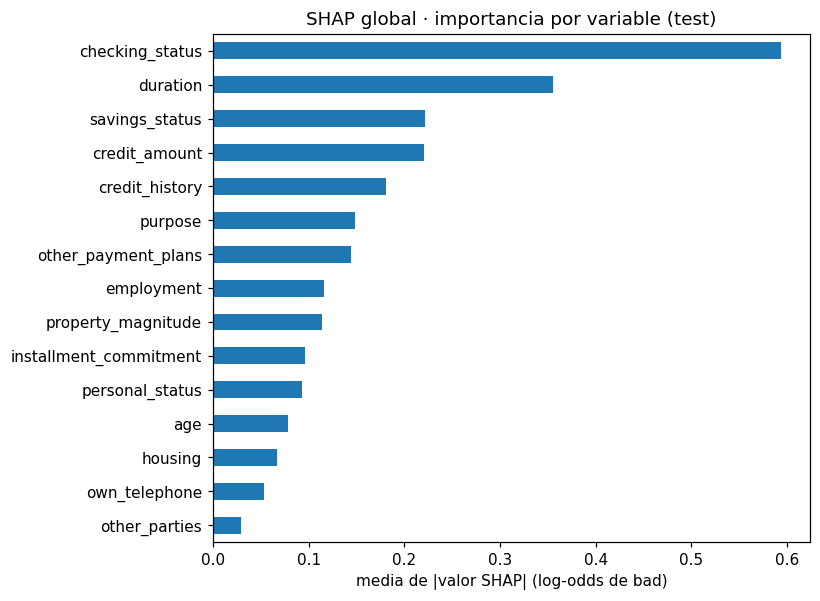

Top-5 global: ['checking_status', 'duration', 'savings_status', 'credit_amount', 'credit_history']


In [64]:
prep, xgb = model.named_steps["prep"], model.named_steps["model"]
ORIGIN = pc.original_var(prep)
# Nombres legibles y válidos para XGBoost (no admite "<", "[" ni "]")
NAMES_T = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
SAFE_T = [n.replace("<", "lt").replace("[", "(").replace("]", ")") for n in NAMES_T]
Xte_t = pd.DataFrame(prep.transform(X_test), columns=SAFE_T, index=X_test.index)

sv = shap.TreeExplainer(xgb)(Xte_t)
sv.feature_names = NAMES_T
shap_test = pc.add_by_var(sv.values, ORIGIN, COLUMNS).set_index(X_test.index)
BASE = float(np.atleast_1d(sv.base_values)[0])

importance = shap_test.abs().mean().sort_values()
storage_csv(importance[::-1].rename("importancia").to_frame(), "importancia_shap")
TOP5_SHAP = importance.index[-5:][::-1].tolist()
plt.figure(figsize=(7, 6))
importance.tail(15).plot.barh(color="#1f77b4")
plt.xlabel("media de |valor SHAP| (log-odds de bad)"); plt.title("SHAP global · importancia por variable (test)")
storage("3_2", "shap_importancia")
print("Top-5 global:", TOP5_SHAP)

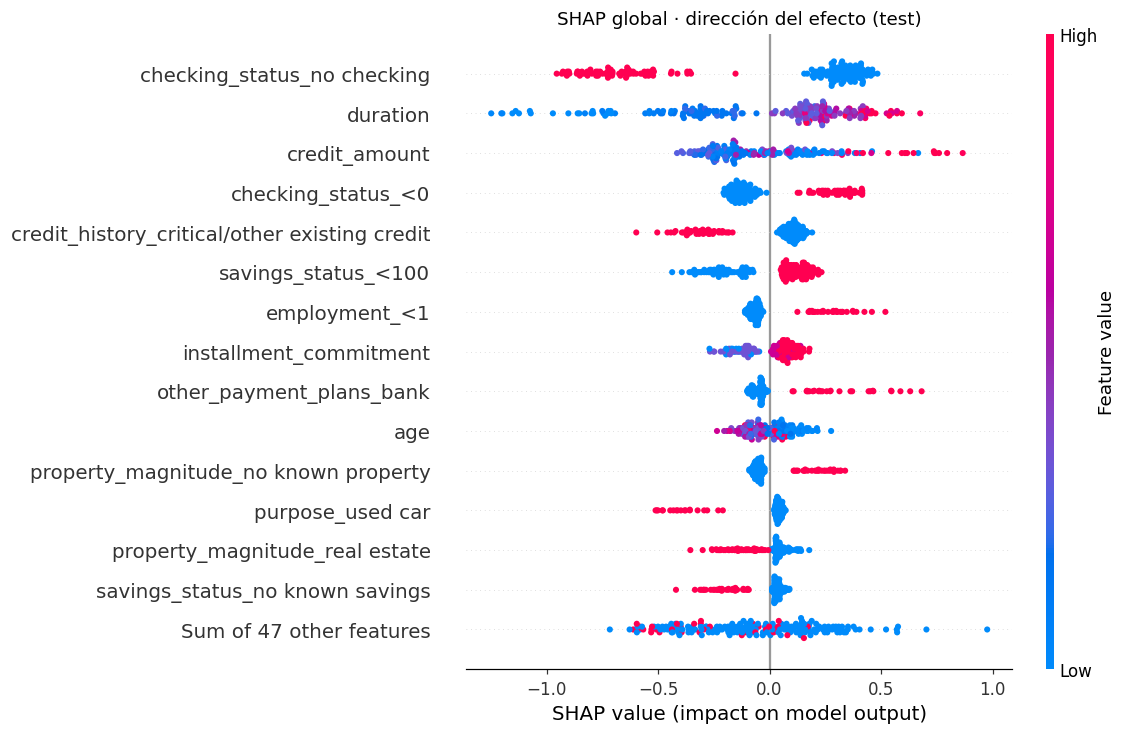

In [65]:
# Dirección del efecto por columna one-hot: cada punto es un solicitante; rojo = valor alto de la columna
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("SHAP global · dirección del efecto (test)")
storage("3_2", "shap_beeswarm")

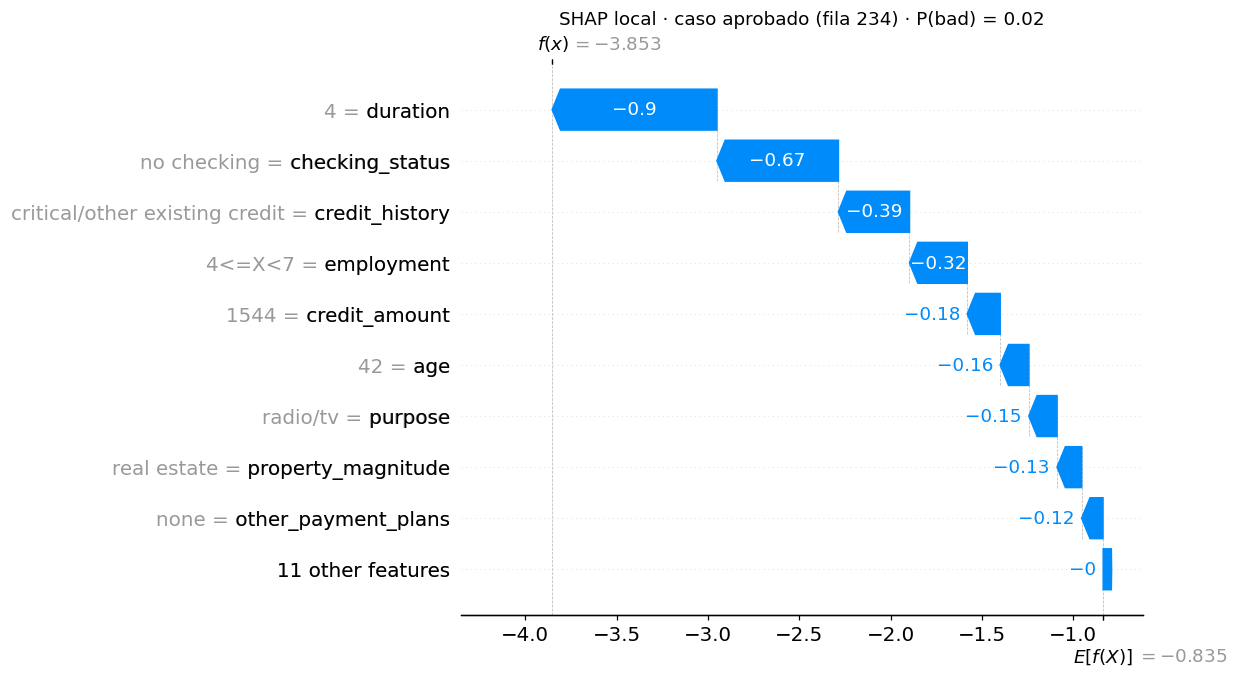

aprobado: base -0.84 + suma SHAP -3.02 = -3.85 -> p = 0.021 (modelo 0.021)


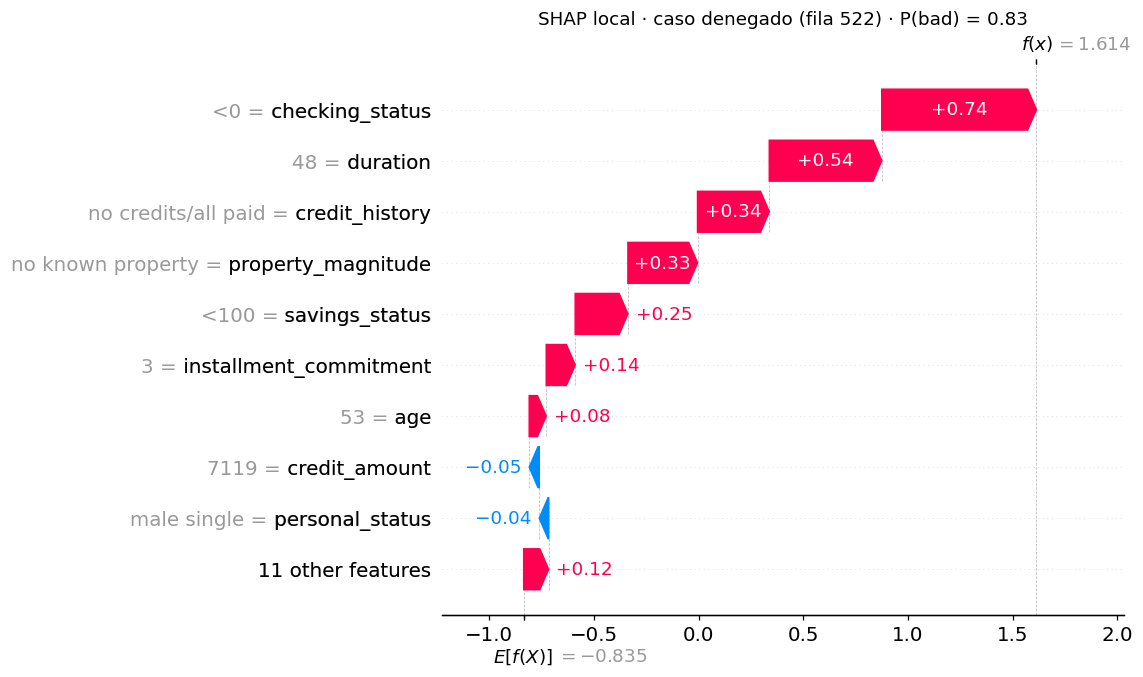

denegado: base -0.84 + suma SHAP +2.45 = +1.61 -> p = 0.834 (modelo 0.834)


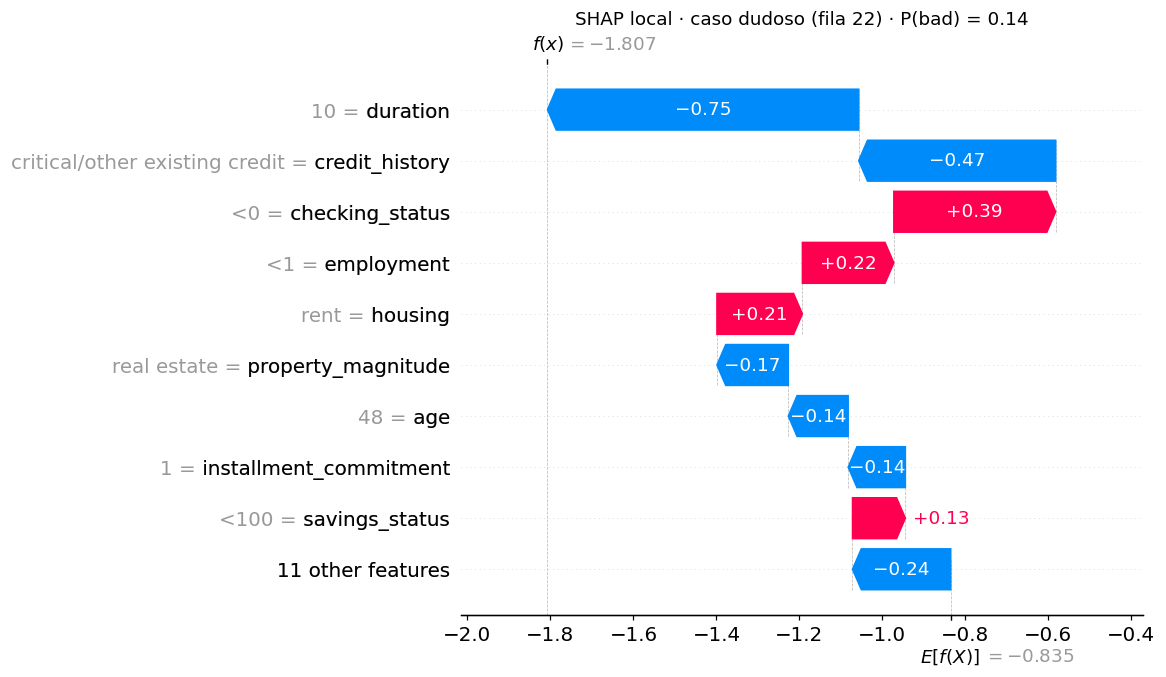

dudoso: base -0.84 + suma SHAP -0.97 = -1.81 -> p = 0.141 (modelo 0.141)


In [66]:
for name, i in CASES.items():
    e = shap.Explanation(values=shap_test.loc[i].values, base_values=BASE,
                         data=X_test.loc[i].astype(str).values, feature_names=COLUMNS)
    shap.plots.waterfall(e, max_display=10, show=False)
    plt.title(f"SHAP local · caso {name} (fila {i}) · P(bad) = {p_test[i]:.2f}")
    storage("4_1", f"caso_{name}_shap")
    # Comprobación: base + suma SHAP = predicción del modelo (en log-odds)
    z = BASE + shap_test.loc[i].sum()
    print(f"{name}: base {BASE:+.2f} + suma SHAP {shap_test.loc[i].sum():+.2f} = {z:+.2f} -> p = {1/(1+np.exp(-z)):.3f} (modelo {p_test[i]:.3f})")

**Interpretación (3.2 / 4.1)**

- **Global:** las variables que más pesan son el saldo de la cuenta corriente (`checking_status`), la duración, los ahorros, el importe y el historial de crédito. Tienen sentido para un banco y coinciden en 4 de 5 con el EBM del subgrupo A (que pone `purpose` en lugar de `credit_amount`). La edad pesa poco de forma directa (puesto 12 de 20).
- **Efecto contraintuitivo:** el historial `critical/other existing credit` (cuenta crítica o créditos en otros bancos) **baja** el riesgo en el modelo. Es lo que hay en los datos (17 % de impagos frente al 62 % de «sin créditos previos»), probablemente por los errores de codificación documentados por Grömping (2019). El subgrupo A detectó lo mismo leyendo directamente sus modelos; aquí solo aparece si se busca con SHAP.
- **Caso aprobado (fila 234, P = 0,02):** préstamo a 4 meses (−0,90), sin cuenta corriente (−0,67) e historial «crítico» (−0,39). Los tres modelos lo conceden.
- **Caso denegado (fila 522, P = 0,83):** saldo negativo (+0,74), 48 meses (+0,54), sin créditos previos (+0,34), sin propiedades conocidas (+0,33) y ahorros < 100 DM (+0,25). Los tres modelos lo deniegan.
- **Caso dudoso (fila 22, P = 0,141, umbral 0,14):** se deniega por muy poco y **es un buen pagador**, así que es un error del modelo. Lo empujan a denegar el saldo negativo (+0,39), menos de un año en el empleo (+0,22) y vivir de alquiler (+0,21); lo salvan la duración corta (−0,75) y, otra vez, el historial «crítico» (−0,47). Los modelos no se ponen de acuerdo: la logística lo concede (acierta) y el EBM y el XGBoost lo deniegan.
- **Lo que garantiza SHAP:** en los tres casos, valor base + suma de valores SHAP = predicción del modelo (comprobado en la salida de la celda). El reparto es exacto, pero SHAP dice **cuánto** pesa cada variable, no **por qué** el modelo le da ese peso: el mecanismo sigue dentro de los 150 árboles.

## 3.5. Estabilidad de SHAP entre reentrenamientos

Mismo modelo reentrenado en 5 particiones distintas del entrenamiento: ¿salen las mismas 5 variables más importantes? (`pc.stability`, Jaccard medio entre pares).

In [67]:
tops = []
for tr, va in StratifiedKFold(pc.N_PARTITION, shuffle=True, random_state=pc.SEED).split(X_train, y_train):
    mk = create_xgb(**BEST)().fit(X_train.iloc[tr], y_train.iloc[tr])
    pr, mo = mk.named_steps["prep"], mk.named_steps["model"]
    v = shap.TreeExplainer(mo)(pr.transform(X_train.iloc[va])).values
    imp = pc.add_by_var(v, pc.original_var(pr), COLUMNS).abs().mean()
    tops.append(imp.sort_values(ascending=False).index[:5].tolist())
STAB_SHAP = pc.stability(tops)
tops_df = pd.DataFrame(tops, index=[f"partición {k+1}" for k in range(len(tops))], columns=[f"#{k+1}" for k in range(5)])
storage_csv(tops_df, "estabilidad_shap")
display(tops_df)
print(f"Estabilidad SHAP global (Jaccard medio del top-5): {STAB_SHAP:.2f}")

,#1,#2,#3,#4,#5
partición 1,checking_status,duration,credit_amount,other_payment_plans,property_magnitude
partición 2,checking_status,duration,credit_amount,savings_status,credit_history
partición 3,checking_status,duration,credit_amount,purpose,credit_history
partición 4,checking_status,duration,credit_history,savings_status,credit_amount
partición 5,checking_status,savings_status,credit_history,duration,installment_commitment


Estabilidad SHAP global (Jaccard medio del top-5): 0.56


## 3.2 / 3.5. LIME y su estabilidad

LIME inventa clientes parecidos al real, mira qué predice el modelo y ajusta una recta que lo imite en esa zona. Para cada caso se ejecuta **10 veces con semillas distintas**:

- **Estabilidad:** ¿salen las mismas 5 variables en cada ejecución?
- **Coincidencia con SHAP:** ¿se parecen las 5 variables de LIME a las de SHAP para el mismo cliente?

En el gráfico de LIME, **verde empuja hacia `bad` (denegar)** y rojo hacia `good`: al revés que en SHAP.

,caso,Estabilidad LIME (10 semillas),Coincidencia LIME–SHAP,Top-5 SHAP,Top-5 LIME (semilla 0)
0,aprobado,0.88,0.62,"duration, checking_status, credit_history, emp...","checking_status, duration, purpose, credit_his..."
1,denegado,0.76,0.43,"checking_status, duration, credit_history, pro...","checking_status, purpose, credit_history, dura..."
2,dudoso,0.83,0.60,"duration, credit_history, checking_status, emp...","checking_status, duration, purpose, credit_his..."


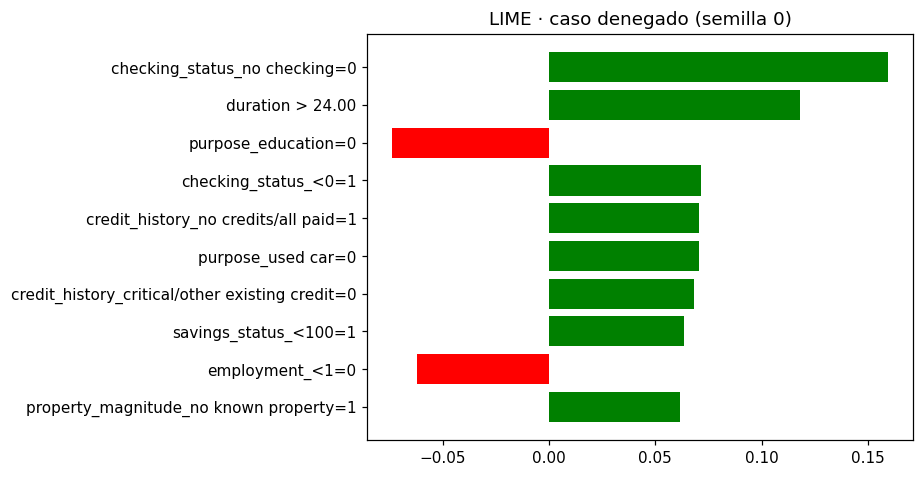

In [68]:
Xtr_t = prep.transform(X_train)
IDX_CAT = [k for k, o in enumerate(ORIGIN) if o in COLS_CAT]

def lime_case(i, seed):
    expl = LimeTabularExplainer(Xtr_t, feature_names=NAMES_T, class_names=["good", "bad"],
                                categorical_features=IDX_CAT, discretize_continuous=True,
                                random_state=seed, mode="classification")
    e = expl.explain_instance(Xte_t.loc[i].values, xgb.predict_proba, num_features=10, labels=(1,))
    weights = pd.Series(0.0, index=sorted({ORIGIN[k] for k, _ in e.as_map()[1]}))
    for k, w in e.as_map()[1]:
        weights[ORIGIN[k]] += abs(w)                 # agrupado por variable original
    return weights.sort_values(ascending=False).index[:5].tolist(), e

rows = []
for name, i in CASES.items():
    tops_lime = [lime_case(i, s)[0] for s in range(10)]
    top_shap = shap_test.loc[i].abs().sort_values(ascending=False).index[:5].tolist()
    rows.append({"caso": name,
                 "Estabilidad LIME (10 semillas)": round(pc.stability(tops_lime), 2),
                 "Coincidencia LIME–SHAP": round(np.mean([pc.jaccard(t, top_shap) for t in tops_lime]), 2),
                 "Top-5 SHAP": ", ".join(top_shap), "Top-5 LIME (semilla 0)": ", ".join(tops_lime[0])})
LIME_TABLE = pd.DataFrame(rows)
storage_csv(LIME_TABLE, "estabilidad_lime_shap", index=False)
display(LIME_TABLE)

lime_case(CASES["denegado"], 0)[1].as_pyplot_figure(label=1)
plt.title("LIME · caso denegado (semilla 0)")
storage("4_1", "caso_denegado_lime")

**Interpretación (3.5)**

- **Estabilidad de SHAP global (0,56):** `checking_status` es la primera en las 5 particiones y `duration` aparece siempre en el top-5, pero el resto del top-5 cambia según con qué datos se entrene. Es menos estable que los modelos del subgrupo A (Jaccard 0,75 el EBM y 0,62 la logística; ojo, A lo calculó con 15 reentrenamientos y B con 5).
- **Estabilidad de LIME (0,76–0,88):** con el mismo cliente y el mismo modelo, cambiar solo la semilla cambia las variables que salen. Es peor justo en el caso denegado (0,76), que es el que el banco tendría que justificar.
- **Coincidencia LIME–SHAP (0,43–0,62):** las dos técnicas comparten solo 2 o 3 de las 5 variables principales para el mismo cliente. LIME mete siempre el propósito del préstamo (`purpose`), que SHAP no destaca. Además, LIME explica con frases del tipo «no tener propósito *educación*» o «no tener propósito *coche usado*», difíciles de trasladar a un cliente.
- **Qué implica:** un banco que use una caja negra puede dar explicaciones distintas para la misma decisión según la técnica (o la semilla) que elija. Slack et al. (2020) demostraron además que se puede construir un modelo que engañe a LIME y a SHAP para ocultar un sesgo. La explicación no es una prueba de cómo decide el modelo.

## 3.2 / 4.1. Explicación contrafactual (DiCE)

Para el caso denegado: **¿qué tendría que cambiar para que se le concediera el crédito?** No se dejan cambiar las variables que el cliente no puede modificar (`pc.INMUTABLES`). Solo se aceptan contrafactuales **por debajo del umbral**; se muestran primero los que necesitan menos cambios.

In [69]:
dice = dice_ml.Dice(dice_ml.Data(dataframe=X_train.assign(bad=y_train.values), continuous_features=COLS_NUM, outcome_name="bad"),
                    dice_ml.Model(model=model, backend="sklearn"), method="random")

def counterfactuals(i, n=3):
    # Varias búsquedas aleatorias. stopping_threshold: P(good) ≥ 1 − umbral, es decir, P(bad) por debajo del umbral
    parts = []
    for k in range(5):
        cf = dice.generate_counterfactuals(X_test.loc[[i]], total_CFs=30, desired_class=0, stopping_threshold=1 - thres,
                                           features_to_vary=[c for c in COLUMNS if c not in pc.INMUTABLES],
                                           random_seed=pc.SEED + k, verbose=False)
        if cf.cf_examples_list[0].final_cfs_df is not None:
            parts.append(cf.cf_examples_list[0].final_cfs_df)
    cand = pd.concat(parts).drop(columns="bad")[COLUMNS].astype(X_train.dtypes.to_dict()).drop_duplicates()
    cand["P(bad)"] = model.predict_proba(cand)[:, 1]
    if (cand["P(bad)"] < thres).any():
        cand = cand[cand["P(bad)"] < thres]
    else:
        print(f"Ningún contrafactual baja del umbral {thres:.2f}: se muestran los más cercanos.")
        cand = cand.nsmallest(n * 3, "P(bad)")
    cand["n.º cambios"] = (cand[COLUMNS] != X_test.loc[i]).sum(axis=1)
    cand = cand.sort_values(["n.º cambios", "P(bad)"]).head(n)
    table = pd.concat([X_test.loc[[i]].assign(**{"P(bad)": p_test[i], "n.º cambios": 0}), cand]).reset_index(drop=True)
    table.index = ["original"] + [f"contrafactual {k+1}" for k in range(len(cand))]
    changed = [c for c in COLUMNS if (table[c] != table.loc["original", c]).any()]
    return table[changed + ["P(bad)", "n.º cambios"]]

CF_TABLE = counterfactuals(CASES["denegado"])
storage_csv(CF_TABLE, "contrafactuales_denegado")
CF_TABLE.round(3)

100%|██████████| 1/1 [00:01<00:00,  1.12s/it]


,checking_status,duration,credit_history,purpose,savings_status,installment_commitment,property_magnitude,P(bad),n.º cambios
original,<0,48,no credits/all paid,furniture/equipment,<100,3,no known property,0.834,0
contrafactual 1,no checking,48,no credits/all paid,used car,>=1000,1,no known property,0.130,4
contrafactual 2,no checking,48,delayed previously,used car,<100,1,no known property,0.135,4
contrafactual 3,<0,6,critical/other existing credit,furniture/equipment,<100,2,real estate,0.139,4


**Interpretación (contrafactuales)**

Los tres contrafactuales necesitan **4 cambios** para pasar de P = 0,83 a menos de 0,14, y varios no tienen sentido como consejo:

- **«No tener cuenta corriente»** (contrafactuales 1 y 2): en estos datos, quien no tiene cuenta impaga poco, así que el modelo premia cerrarla. Decirle a un cliente que cierre su cuenta para obtener un crédito es absurdo.
- **Empeorar el historial ayuda:** el contrafactual 2 pasa de «sin créditos previos» a «retrasos en el pasado», y el 3 a «cuenta crítica / créditos en otros bancos». Es el efecto contraintuitivo del historial otra vez.
- **Cambiar el propósito** (de muebles a coche usado) no es mejorar la solicitud, es pedir otra cosa.
- **Combinaciones incoherentes:** el contrafactual 3 reduce la duración de 48 a 6 meses con el mismo importe (7.119 DM) y a la vez baja la cuota sobre la renta (de 3 a 2). En la realidad, devolver lo mismo en 6 meses dispararía la cuota. DiCE cambia variables por separado sin saber cómo se relacionan.

Conclusión: la explicación es **fiel al modelo**, y justo por eso deja al descubierto que el modelo ha aprendido relaciones raras de los datos. Para el cliente, una explicación accionable de verdad necesitaría restricciones que DiCE no conoce.

## 4.2. Sesgos por edad

Con `pc.equity` (≤25 frente a >25 años). Igual que el subgrupo A: el **test** se guarda para la comparación final y también se calcula con las predicciones **fuera de muestra** de la validación cruzada (800 casos, más fiable). El cociente de concesión jóvenes/mayores se compara con la regla de los 4/5 (≥ 0,8).

Test:


,Tasa de concesión,Buenos denegados,Malos detectados,n
grupo de edad,,,,
>25 años,0.321,0.595,0.925,156.0
≤25 años,0.205,0.708,0.900,44.0
diferencia,0.116,0.114,0.025,NaN


Cociente de concesión jóvenes/mayores: 0.64
Validación cruzada (fuera de muestra):


,Tasa de concesión,Buenos denegados,Malos detectados,n
grupo de edad,,,,
>25 años,0.361,0.536,0.911,654.0
≤25 años,0.130,0.791,0.983,146.0
diferencia,0.231,0.255,0.072,NaN


Cociente de concesión jóvenes/mayores: 0.36


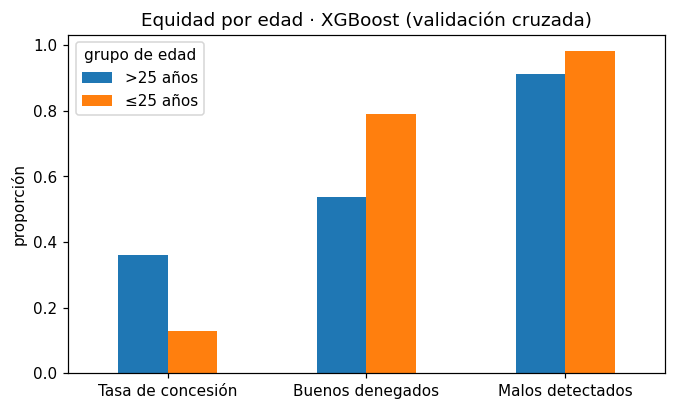

In [70]:
def ratio(t):
    return t.loc[f"≤{pc.CUTOFF_AGE} años", "Tasa de concesión"] / t.loc[f">{pc.CUTOFF_AGE} años", "Tasa de concesión"]

EQ_TEST = pc.equity(y_test, p_test, X_test["age"], thres)
EQ_CV = pc.equity(y_train, oof, X_train["age"], thres)
pc.storage_equity(FOLDER, SUBGROUP, MODEL, EQ_TEST)
EQ_CV.assign(modelo=MODEL).to_csv(os.path.join(R["results"], f"equidad_cv_{SUBGROUP}_{MODEL}.csv"))

print("Test:"); display(EQ_TEST.round(3)); print(f"Cociente de concesión jóvenes/mayores: {ratio(EQ_TEST):.2f}")
print("Validación cruzada (fuera de muestra):"); display(EQ_CV.round(3)); print(f"Cociente de concesión jóvenes/mayores: {ratio(EQ_CV):.2f}")

EQ_CV.drop(index="diferencia")[["Tasa de concesión", "Buenos denegados", "Malos detectados"]].T.plot.bar(rot=0, figsize=(7, 4))
plt.ylabel("proporción"); plt.title("Equidad por edad · XGBoost (validación cruzada)")
storage("4_2", "equidad_edad")

**¿Y si quitamos la edad?** Igual que hizo el subgrupo A con sus modelos: se reentrena sin la variable `age` y se mira si la diferencia entre grupos se reduce. Si no se reduce, otras variables están haciendo de aproximación de la edad (*proxies*).

In [71]:
Xtr_noage = X_train.drop(columns="age")
create_noage = lambda: Pipeline([
    ("prep", pc.create_preprocess(Xtr_noage)),
    ("model", XGBClassifier(**BEST, subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
                            random_state=pc.SEED, n_jobs=-1))])
tcv_s, th_s, oof_s = pc.evaluate_cv(create_noage, Xtr_noage, y_train)
eq_s = pc.equity(y_train, oof_s, X_train["age"], th_s)
NO_AGE = pd.DataFrame([
    {"versión": v, "AUC CV": t["AUC"].mean(), "Coste CV": t["Coste medio"].mean(),
     "dif. concesión": e.loc["diferencia", "Tasa de concesión"], "cociente concesión": ratio(e),
     "dif. buenos denegados": e.loc["diferencia", "Buenos denegados"],
     "dif. malos detectados": e.loc["diferencia", "Malos detectados"]}
    for v, t, e in [("con edad", table_cv, EQ_CV), ("sin edad", tcv_s, eq_s)]]).assign(modelo=MODEL)
storage_csv(NO_AGE, "sin_edad", index=False)
NO_AGE.round(3)

,versión,AUC CV,Coste CV,dif. concesión,cociente concesión,dif. buenos denegados,dif. malos detectados,modelo
0,con edad,0.792,0.523,0.231,0.361,0.255,0.072,XGBoost
1,sin edad,0.792,0.519,0.160,0.485,0.159,0.050,XGBoost


**Interpretación (4.2)**

- **Sí, se concede mucho menos a los jóvenes.** En validación cruzada se concede al 13 % de los menores de 25 frente al 36 % de los mayores: cociente 0,36, muy por debajo de 0,8 (regla de los 4/5). Y entre los que **sí pagan**, se deniega al 79 % de los jóvenes frente al 54 % de los mayores. En test el cociente es 0,64, pero solo hay 44 jóvenes, así que es menos fiable.
- **Parte viene de los datos:** los jóvenes impagan más (42 % frente a 27 %). Pero el XGBoost **amplifica** la diferencia más que los modelos del subgrupo A, con los mismos datos: cociente 0,36 frente a 0,60 de la logística y 0,42 del EBM.
- **Quitar la edad:** el cociente mejora de 0,36 a 0,49 **sin perder precisión** (AUC 0,792 en las dos versiones; el coste incluso baja de 0,523 a 0,519). La edad no aporta nada al rendimiento y sí empeora la equidad. Aun así, sigue lejos de 0,8: otras variables relacionadas con la edad (antigüedad en el empleo, vivienda, estado civil) hacen de aproximación (*proxies*). Al subgrupo A le pasa lo mismo (0,62 la logística y 0,50 el EBM sin edad).

## 4.3. Lista de comprobación de auditoría

Primera valoración del XGBoost con la evidencia de este notebook. ✏️ **Revisadla en grupo** antes de darla por buena.

In [72]:
for q in pc.AUDIT_LIST:
    print(q)

1. ¿Se puede reproducir una decisión concreta a mano o con una fórmula documentada?
2. ¿Se puede revisar el modelo completo con un número manejable de elementos (coeficientes, reglas, nodos)?
3. ¿La explicación sale del propio modelo o de una aproximación externa?
4. ¿La explicación es estable entre ejecuciones o particiones (Jaccard del top-5)?
5. ¿Se puede ver qué peso tienen las variables sensibles o sus aproximaciones (edad, estado civil)?
6. ¿Se puede comprobar la equidad por grupos de edad?
7. ¿Se puede detectar un comportamiento ilógico del modelo (efectos contraintuitivos)?
8. ¿Puede el solicitante recibir una explicación útil y accionable (qué tendría que cambiar)?
9. ¿Está documentado con una model card completa?


In [73]:
AUDIT = [
    ("No", "La predicción sale de cientos de árboles combinados; no se puede rehacer a mano. Solo se puede comprobar que la suma de SHAP coincide con la predicción."),
    ("No", f"{BEST['n_estimators']} árboles de profundidad {BEST['max_depth']}; para resumirlo hay que fiarse de SHAP o LIME."),
    ("No", "SHAP, LIME y DiCE son técnicas externas que describen o aproximan el modelo desde fuera."),
    ("Parcial", f"SHAP global: Jaccard {STAB_SHAP:.2f} entre reentrenamientos. LIME por caso: " +
                ", ".join(f"{r['caso']} {r['Estabilidad LIME (10 semillas)']}" for _, r in LIME_TABLE.iterrows()) +
                ". LIME y SHAP coinciden solo en parte."),
    ("Parcial", "SHAP muestra el peso de age y personal_status, pero las interacciones entre árboles pueden ocultar aproximaciones (proxies)."),
    ("Sí", f"Con pc.equity: cociente de concesión jóvenes/mayores {ratio(EQ_CV):.2f} en validación cruzada."),
    ("Parcial", "Los efectos raros solo aparecen si se buscan con SHAP o con contrafactuales (ver el contrafactual del caso denegado)."),
    ("Parcial", "DiCE da cambios accionables respetando las variables inmutables, pero dependen de la semilla y pueden no tener sentido para el cliente."),
    ("Parcial", "Borrador de model card generado en results/; falta revisarlo y completarlo."),
]
pc.storage_auditory(FOLDER, SUBGROUP, MODEL, AUDIT)

,valoración,evidencia
pregunta,,
1. ¿Se puede reproducir una decisión concreta a mano o con una fórmula documentada?,No,La predicción sale de cientos de árboles combi...
"2. ¿Se puede revisar el modelo completo con un número manejable de elementos (coeficientes, reglas, nodos)?",No,150 árboles de profundidad 4; para resumirlo h...
3. ¿La explicación sale del propio modelo o de una aproximación externa?,No,"SHAP, LIME y DiCE son técnicas externas que de..."
4. ¿La explicación es estable entre ejecuciones o particiones (Jaccard del top-5)?,Parcial,SHAP global: Jaccard 0.56 entre reentrenamient...
"5. ¿Se puede ver qué peso tienen las variables sensibles o sus aproximaciones (edad, estado civil)?",Parcial,"SHAP muestra el peso de age y personal_status,..."
6. ¿Se puede comprobar la equidad por grupos de edad?,Sí,Con pc.equity: cociente de concesión jóvenes/m...
7. ¿Se puede detectar un comportamiento ilógico del modelo (efectos contraintuitivos)?,Parcial,Los efectos raros solo aparecen si se buscan c...
8. ¿Puede el solicitante recibir una explicación útil y accionable (qué tendría que cambiar)?,Parcial,DiCE da cambios accionables respetando las var...
9. ¿Está documentado con una model card completa?,Parcial,Borrador de model card generado en results/; f...


## 4.3. *Model card* (borrador)

Se guarda en `results/model_card_B_XGBoost.md`. Completad las partes con ✏️ antes de pasarla a la subwiki.

In [74]:
import xgboost
metric_rows = "\n".join(f"| {k} | {pc.summary_csv(table_cv)[k]} | {res_test[k]:.3f} |" for k in res_test)
grant = EQ_CV["Tasa de concesión"]
MODEL_CARD = f'''# Model card · XGBoost para riesgo de impago (subgrupo B)

## Detalles del modelo
- Tipo: gradient boosting (XGBoost {xgboost.__version__}) con preprocesado one-hot del protocolo común.
- Hiperparámetros: {BEST}, subsample 0.8, colsample_bytree 0.8, semilla {pc.SEED}.
- Explicaciones: SHAP (TreeSHAP), LIME y contrafactuales (DiCE).
- Autoría: subgrupo B, seminario IAO 2026/27. ✏️ nombres

## Uso previsto
- Uso académico: comparar una caja negra explicada con modelos interpretables por diseño (subgrupo A).
- No apto para decisiones reales de crédito.

## Datos
- Statlog German Credit (UCI / OpenML credit-g): 1.000 solicitantes, 20 variables, 30 % de impagos.
- Partición común 80/20 estratificada; validación cruzada {pc.N_PARTITION}×{pc.N_REPETITION} sobre el 80 %.
- Limitaciones: datos antiguos, pocos casos, errores de codificación (Grömping, 2019); el sexo no se puede obtener de forma fiable.

## Métricas (clase positiva = bad; umbral {thres:.2f} por mínimo coste; costes {pc.FN_COST}:{pc.FP_COST})
| Métrica | Validación cruzada | Test |
|---|---|---|
{metric_rows}

## Explicaciones
- Top-5 SHAP global: {", ".join(TOP5_SHAP)}.
- Estabilidad SHAP entre reentrenamientos (Jaccard top-5): {STAB_SHAP:.2f}.
- Estabilidad LIME por caso (Jaccard top-5, 10 semillas): {", ".join(f"{r['caso']} {r['Estabilidad LIME (10 semillas)']}" for _, r in LIME_TABLE.iterrows())}.

## Equidad (≤{pc.CUTOFF_AGE} frente a >{pc.CUTOFF_AGE} años, validación cruzada)
- Tasa de concesión: {grant.iloc[0]:.2f} frente a {grant.iloc[1]:.2f}; cociente jóvenes/mayores {ratio(EQ_CV):.2f}.
- Sin la variable edad: cociente {ratio(eq_s):.2f}.

## Consideraciones éticas y limitaciones
- La edad se usa como variable de entrada. No mejora el rendimiento (AUC {table_cv["AUC"].mean():.3f} con edad y {tcv_s["AUC"].mean():.3f} sin ella) y empeora la equidad (cociente {ratio(EQ_CV):.2f} con edad y {ratio(eq_s):.2f} sin ella). Quitarla no basta: otras variables hacen de aproximación.
- El modelo ha aprendido efectos contraintuitivos de los datos (el historial «crítico» y no tener cuenta corriente bajan el riesgo) que aparecen en sus explicaciones y en los contrafactuales.
- Las explicaciones post-hoc describen el modelo desde fuera: LIME es inestable y coincide solo en parte con SHAP, y ambas pueden manipularse (Slack et al., 2020).
- Según el AI Act (anexo III), evaluar la solvencia de personas físicas es un sistema de alto riesgo: exige documentación técnica, gestión de datos y sesgos, transparencia y supervisión humana. Este modelo no las cumpliría sin una supervisión humana de las denegaciones y un control de la equidad por edad.
'''
with open(os.path.join(R["results"], f"model_card_{SUBGROUP}_{MODEL}.md"), "w", encoding="utf-8") as f:
    f.write(MODEL_CARD)
print(MODEL_CARD)

# Model card · XGBoost para riesgo de impago (subgrupo B)

## Detalles del modelo
- Tipo: gradient boosting (XGBoost 3.4.1) con preprocesado one-hot del protocolo común.
- Hiperparámetros: {'max_depth': 4, 'n_estimators': 150, 'learning_rate': 0.03}, subsample 0.8, colsample_bytree 0.8, semilla 42.
- Explicaciones: SHAP (TreeSHAP), LIME y contrafactuales (DiCE).
- Autoría: subgrupo B, seminario IAO 2026/27. ✏️ nombres

## Uso previsto
- Uso académico: comparar una caja negra explicada con modelos interpretables por diseño (subgrupo A).
- No apto para decisiones reales de crédito.

## Datos
- Statlog German Credit (UCI / OpenML credit-g): 1.000 solicitantes, 20 variables, 30 % de impagos.
- Partición común 80/20 estratificada; validación cruzada 5×3 sobre el 80 %.
- Limitaciones: datos antiguos, pocos casos, errores de codificación (Grömping, 2019); el sexo no se puede obtener de forma fiable.

## Métricas (clase positiva = bad; umbral 0.14 por mínimo coste; costes 5:1)
| Métrica | Vali

## 3.5. Análisis crítico

> Borrador redactado a partir de los resultados de este notebook y de los del subgrupo A. Revisadlo en grupo antes de pasarlo a la subwiki.

- **¿Es fiel al modelo?** SHAP (TreeSHAP) sí lo es en el reparto: la suma cuadra exactamente con la predicción. Pero describe el resultado, no el mecanismo, y LIME, que es una aproximación, coincide con SHAP solo en 2–3 de 5 variables.
- **¿Es estable?** A medias: SHAP global 0,56 entre reentrenamientos (por debajo de los modelos de A), LIME cambia con la semilla y DiCE da contrafactuales distintos según la búsqueda.
- **¿Se puede manipular?** Sí, en principio (Slack et al., 2020). Lo más preocupante es que quien recibe la explicación no tiene forma de comprobarla, porque el modelo no se puede leer.
- **¿Es fácil de auditar y documentar?** Hace falta combinar tres técnicas, comprobar que coinciden y buscar activamente los efectos raros. Los modelos del subgrupo A permiten hacer lo mismo leyendo una tabla de coeficientes o unas curvas.
- **¿Compensa?** En este problema, no se aprecia: el XGBoost no mejora de forma clara la precisión (diferencias dentro del ruido) y es el que más perjudica a los jóvenes. Es un resultado de **estos datos** (pocos casos, variables tabulares sencillas); con datos más grandes o relaciones más complejas la caja negra podría sacar más ventaja, y eso habría que comprobarlo, no suponerlo.

In [75]:
sorted(f for f in os.listdir(R["results"]) if "_B_" in f), sorted(f for f in os.listdir(R["graphics"]) if f.startswith("B_"))

(['auditoria_B_XGBoost.csv',
  'busqueda_hiperparametros_B_XGBoost.csv',
  'casos_B_XGBoost.csv',
  'contrafactuales_denegado_B_XGBoost.csv',
  'equidad_B_XGBoost.csv',
  'equidad_cv_B_XGBoost.csv',
  'estabilidad_lime_shap_B_XGBoost.csv',
  'estabilidad_shap_B_XGBoost.csv',
  'importancia_shap_B_XGBoost.csv',
  'model_card_B_XGBoost.md',
  'predicciones_B_XGBoost.csv',
  'resultados_B_XGBoost.csv',
  'sin_edad_B_XGBoost.csv'],
 ['B_3_2_XGBoost_shap_beeswarm.png',
  'B_3_2_XGBoost_shap_importancia.png',
  'B_3_4_XGBoost_matriz_confusion.png',
  'B_4_1_XGBoost_caso_aprobado_shap.png',
  'B_4_1_XGBoost_caso_denegado_lime.png',
  'B_4_1_XGBoost_caso_denegado_shap.png',
  'B_4_1_XGBoost_caso_dudoso_shap.png',
  'B_4_2_XGBoost_equidad_edad.png'])